# Sense Analysis


In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()


## Saved Evaluation Results

The English transfer experiment used the full English corpus; English tuning was evaluated on heldout words. Compare results on matching word sets when assessing the effect of tuning.

The original SV comparison CSV does not include Blend. Its expected prediction file, `outputs/predictions/SV/development_blended.jsonl`, is not currently present.


### SV with SV Settings


In [ ]:
SV_results = pd.read_csv(
    PROJECT_ROOT / "outputs" / "evaluations" / "SV"
    / "subtask1_development_comparison.csv"
)

SV_results


### English with SV Settings


In [ ]:
english_SV_settings_results = pd.read_csv(
    PROJECT_ROOT / "outputs" / "evaluations" / "ENG"
    / "subtask1_english_with_SV_settings.csv"
)

english_SV_settings_results


### English Heldout with English Settings


In [ ]:
english_heldout_results = pd.read_csv(
    PROJECT_ROOT / "outputs" / "evaluations" / "ENG"
    / "subtask1_heldout_comparison.csv"
)

english_heldout_results


### SV with English Settings


In [ ]:
SV_english_settings_results = pd.read_csv(
    PROJECT_ROOT / "outputs" / "evaluations" / "SV"
    / "subtask1_SV_with_english_settings.csv"
)

SV_english_settings_results


## Existing SV Sense Analysis


In [ ]:
hierarchical_development = pd.read_json(
    PROJECT_ROOT / "outputs" / "predictions" / "SV"
    / "development_hierarchical.jsonl",
    lines=True,
)

SV_usages = pd.read_json(
    PROJECT_ROOT / "data" / "raw" / "development-swedish" / "usages.jsonl",
    lines=True,
)

data_by_word = {
    word: rows.copy() for word, rows in SV_usages.groupby("word")
}


####Visualize how the predicted sense distribution of motiv changes across time periods.

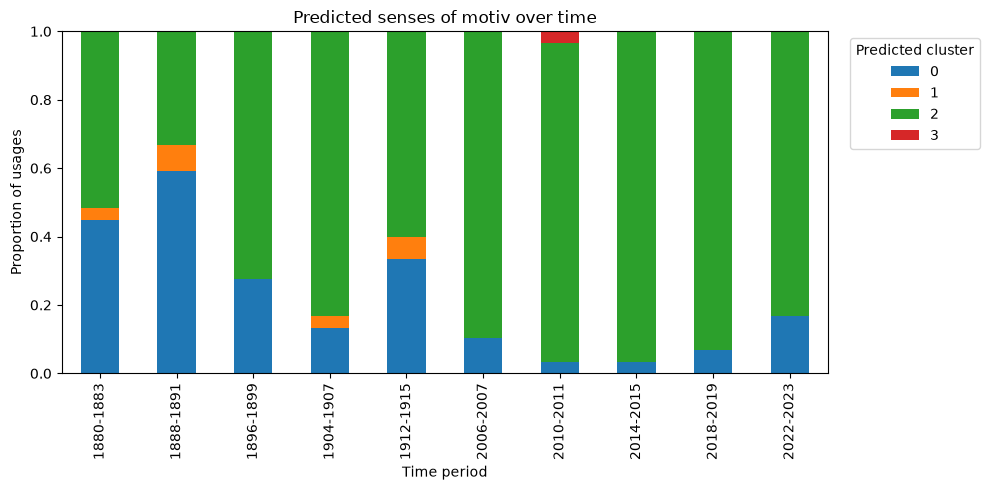

In [55]:
import matplotlib.pyplot as plt

motiv_predictions = hierarchical_development.loc[
    hierarchical_development["word"] == "motiv"
].copy()

motiv_predictions["cluster"] = motiv_predictions["label"].apply(
    lambda labels: labels[0]
)

sense_counts = pd.crosstab(
    motiv_predictions["period_label"],
    motiv_predictions["cluster"]
).sort_index()

sense_proportions = sense_counts.div(
    sense_counts.sum(axis=1), axis=0
)

sense_proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Predicted senses of motiv over time")
plt.xlabel("Time period")
plt.ylabel("Proportion of usages")
plt.legend(title="Predicted cluster", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

####Inspect examples from each predicted cluster to interpret the temporal pattern.

In [56]:
motiv_examples = data_by_word["motiv"].merge(
    motiv_predictions[
        ["word", "period_label", "sentence_id", "cluster"]
    ],
    on=["word", "period_label", "sentence_id"],
    validate="one_to_one"
)

for cluster, rows in motiv_examples.groupby("cluster"):
    print(f"\nCluster {cluster} — {len(rows)} usages")

    examples = rows.sample(
        n=min(4, len(rows)),
        random_state=42
    )

    for _, row in examples.iterrows():
        print(f"{row['year']}: {row['text']}")


Cluster 0 — 63 usages
2006: 39.000 barn från fem år till femte klass ska avgöra om en ny barnspårvagn ska få djungel- , rymd- eller spök- motiv .
1881: Ett annat ledande motiv återfinnes i det stora , derpå följande recitativet , hvari Gurnemanz skildrar detta ridderskaps och Graal-templets uppkomst .
1915: Någon » midsommardans » af det slag , som man ser på konstnärernas motiv frän just denna till:ti ; .-i , n " i kan oc . "
2022: Mellan 2005 och 2009 tog Moll tusentals bilder från Tibbleberget och resultatet är nu fem panoramabilder , fem meter långa och en meter höga , med motiv från de fyra årstiderna i dagsljus samt en sommarnattsbild .

Cluster 1 — 6 usages
1889: I lagförslagets motiv frambålles , att man skall följa de ledande grundsatserna för den tyska kolo nialpolitik , som riksdagen gillade 1884 och 1885 .
1906: Stämman beslöt att som sin förklaring uttala , att den , vidhållande i alla delar pröfningsnämndens motiv , ansåg , att pröfningsnämndens beslut borde få bestå .
1

#### some simple eda - main sense and stuff (ty)

##### correct ones and sens #

In [ ]:
import pandas as pd

answers = pd.read_json("../data/raw/development-swedish/subtask1.jsonl", lines=True)
answers["sense"] = answers["label"].str[0]
answers.head()

#### seeing num of seses of each word and how common it is  & summary - by most mixed/jumbled to most centered on one sense

In [ ]:
all_senses = answers.explode("label")
counts = all_senses.groupby("word")["label"].value_counts()
sentences = answers["word"].value_counts()

summary = pd.DataFrame({
    "num_senses": all_senses.groupby("word")["label"].nunique(),
    "top_share": (counts.groupby("word").max() / sentences).round(2)
})
summary.sort_values("top_share")

## Saved Blend Predictions for Further Analysis

The English predictions made with SV settings cover the full corpus. Predictions made with English-selected settings cover only the English heldout words. The SV predictions below cover all SV words using English-selected settings.


In [ ]:
english_SV_settings_blend_predictions = pd.read_json(
    PROJECT_ROOT / "outputs" / "predictions" / "ENG"
    / "swedish_settings" / "blend.jsonl",
    lines=True,
)

english_heldout_blend_predictions = pd.read_json(
    PROJECT_ROOT / "outputs" / "predictions" / "ENG"
    / "blend_heldout_predictions.jsonl",
    lines=True,
)

SV_english_settings_blend_predictions = pd.read_json(
    PROJECT_ROOT / "outputs" / "predictions" / "SV"
    / "english_settings" / "blend.jsonl",
    lines=True,
)
